In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import math
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Uploaded file: {filename}")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving boat1.jpg to boat1.jpg
Saving boat2.jpg to boat2.jpg
Saving boat3.jpg to boat3.jpg
Saving boat4.jpg to boat4.jpg
Saving boat5.jpg to boat5.jpg
Saving boat6.jpg to boat6.jpg
Uploaded file: boat1.jpg
Uploaded file: boat2.jpg
Uploaded file: boat3.jpg
Uploaded file: boat4.jpg
Uploaded file: boat5.jpg
Uploaded file: boat6.jpg

Contents Of Images Folder:
['boat6.jpg', 'boat1.jpg', 'boat3.jpg', 'boat5.jpg', 'boat4.jpg', 'boat2.jpg']


In [3]:
imagefiles = glob.glob('images/*')

images = []
for filename in imagefiles:
  img = cv2.imread(filename)
  images.append(img)

num_images = len(images)
print(f"Number Of Images: {num_images}")

Number Of Images: 6


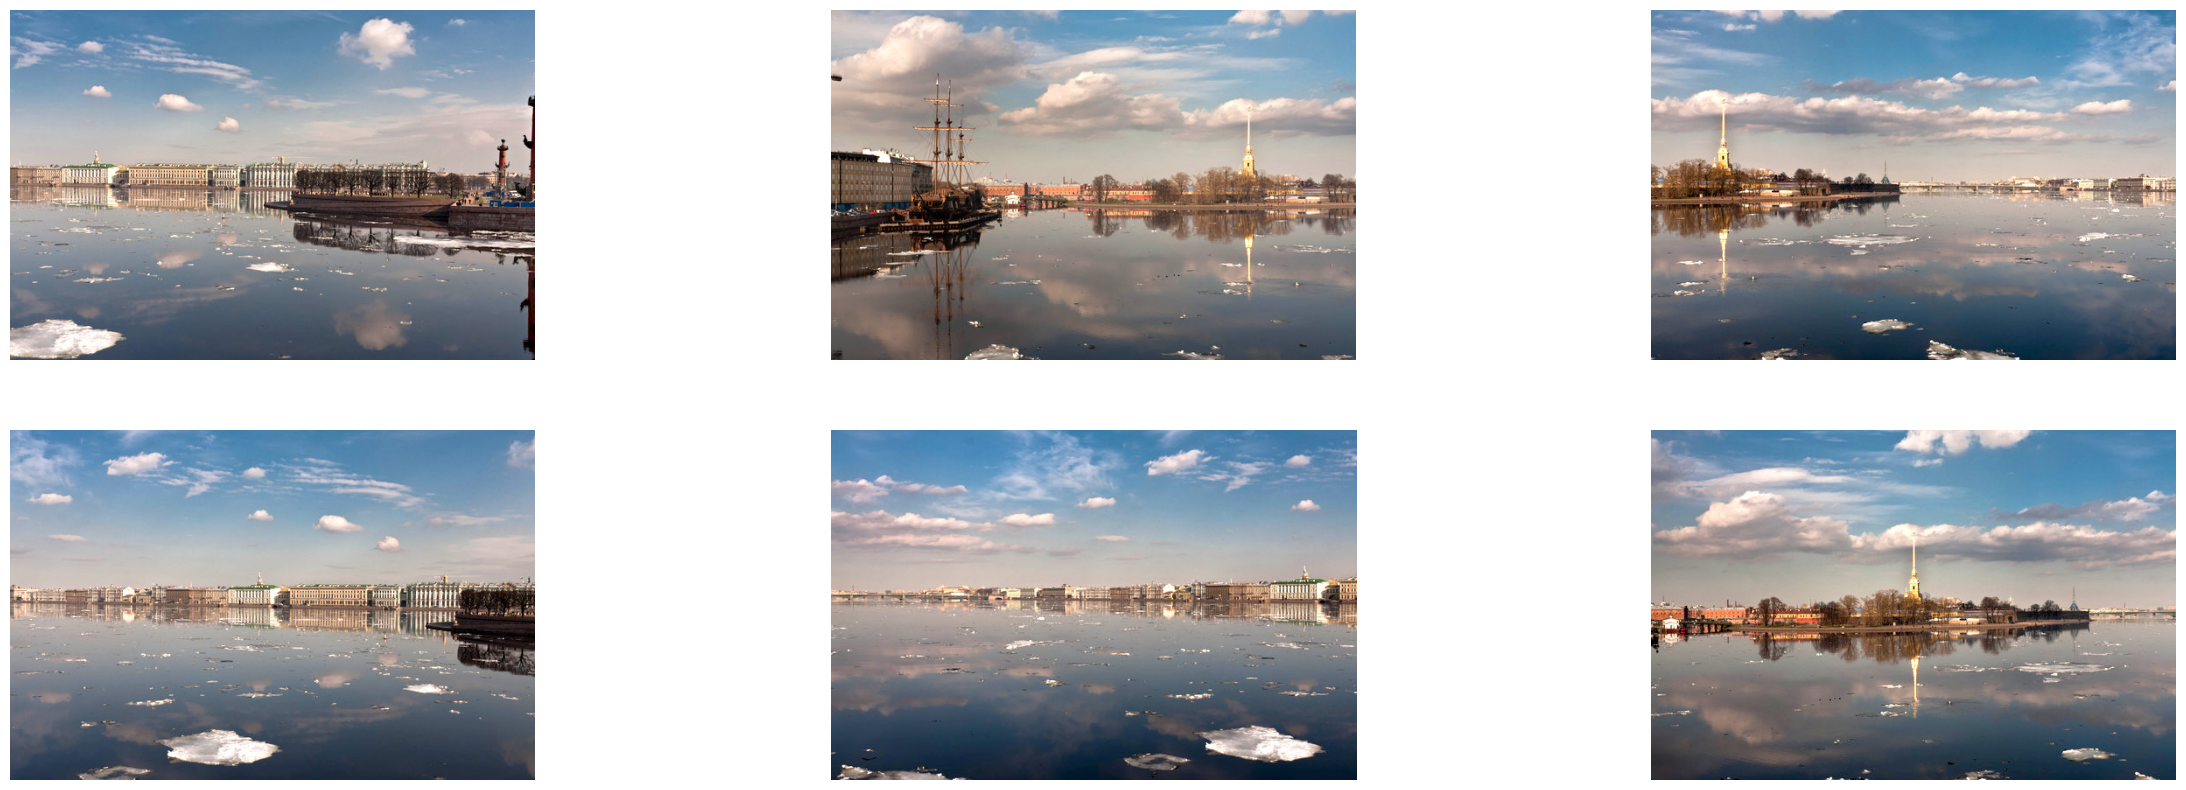

In [4]:
plt.figure(figsize=(30, 10))

num_cols = 3
num_rows = math.ceil(num_images / num_cols)

for i in range(0, num_images):
  plt.subplot(num_rows, num_cols, i + 1)
  plt.imshow(images[i][..., ::-1])
  plt.axis('off')

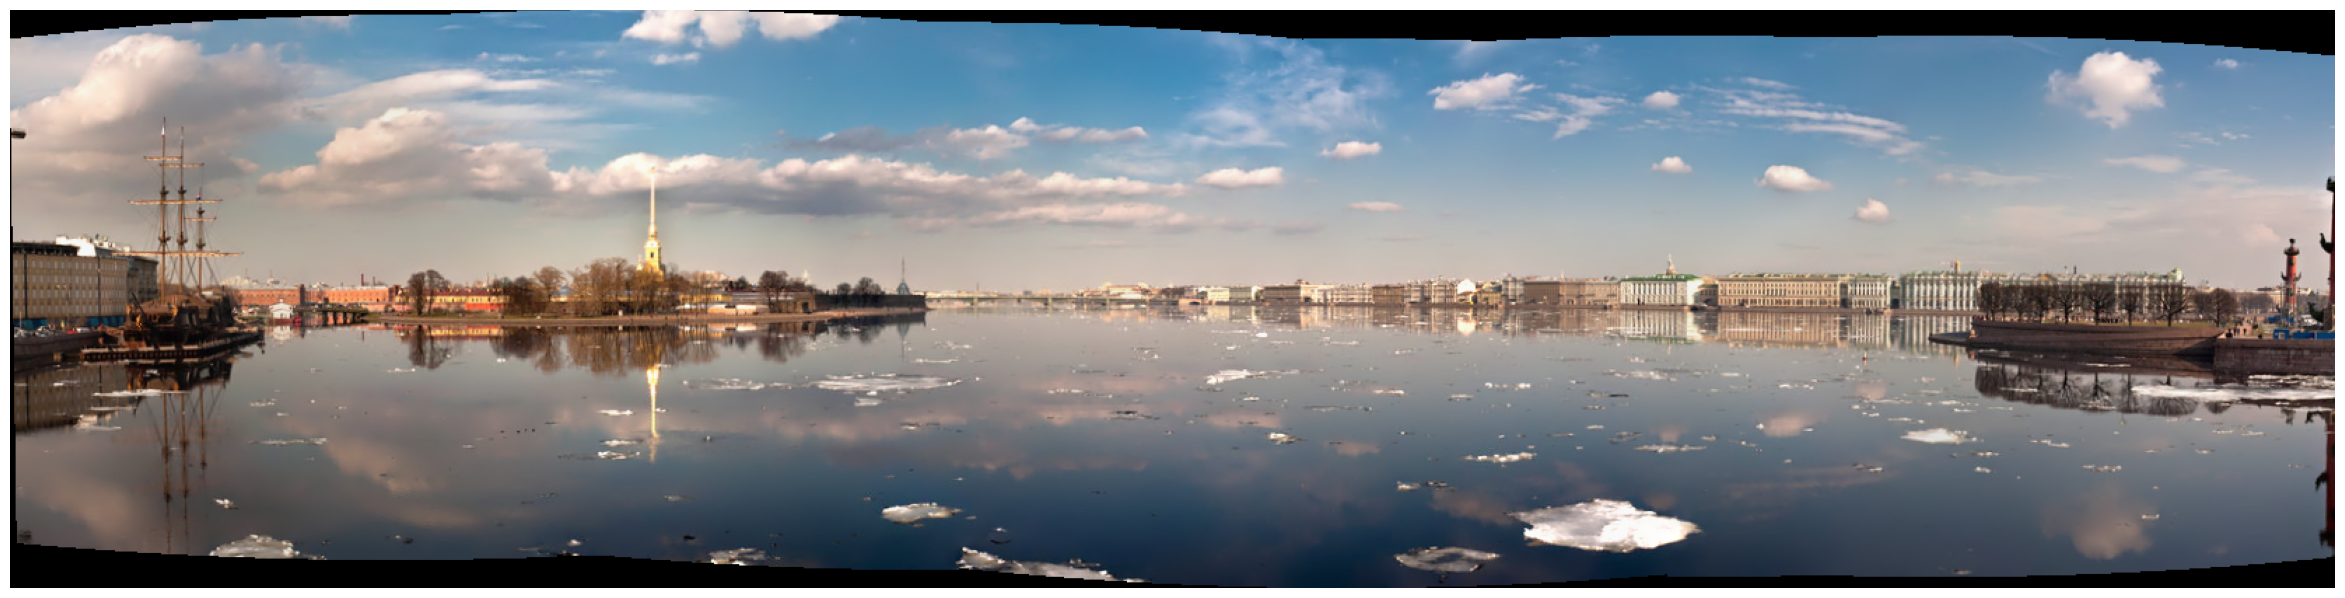

In [5]:
stitcher = cv2.Stitcher_create()

status, result = stitcher.stitch(images)

if status == 0:
  plt.figure(figsize=(30, 10))
  plt.imshow(result[..., ::-1])
  plt.axis('off')
else:
  print("Stitching Failed")